# EDA

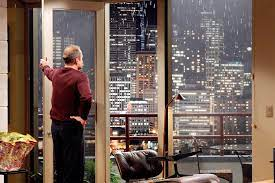

**Überarbeitete Fassung.** Dieses Notebook ist die überarbeitete Version von `04_eda.ipynb`. Das Original bleibt unverändert. Grundlage der Überarbeitung ist ein Review von ChatGPT/Codex. Jeder Kritikpunkt wurde hier an den tatsächlichen Daten geprüft, nicht ungeprüft übernommen. Alle Änderungen mit Begründung stehen in `review_vergleich.md`.

## 0. Setup

In [1]:
import os
import warnings
from importlib.metadata import version

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 5), "axes.facecolor": "white", "figure.facecolor": "w",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", lambda x: "%.3f" % x)

SEED = 42                      # fester Startwert für alle Zufallsverfahren (Bootstrap)
rng = np.random.default_rng(SEED)
BLAU = "#2b6cb0"
GRAU = "#a0aec0"
AUSGABE = "bilder/review"      # neue Diagramme, das Original schreibt nach bilder/
os.makedirs(AUSGABE, exist_ok=True)

for paket in ["pandas", "numpy", "matplotlib", "seaborn", "statsmodels", "plotly"]:
    print(f"{paket:12s} {version(paket)}")

pandas       3.0.3
numpy        2.4.6
matplotlib   3.10.9
seaborn      0.13.2
statsmodels  0.15.0
plotly       6.8.0


In [2]:
def speichern(fig, name):
    """Speichert ein Diagramm für die Präsentation in bilder/review/."""
    fig.savefig(f"{AUSGABE}/{name}.png", dpi=150, bbox_inches="tight")


def prozent(faktor):
    """Wandelt einen Faktor aus dem Log-Modell in Prozent um."""
    return 100 * (np.exp(faktor) - 1)

## 1. Kunde und Fragestellung

**Kunde:** Charles Christensen, Verkäufer. Investiert mit dem Ziel hoher Rendite, überlegt zu renovieren, fragt nach dem richtigen Viertel und dem richtigen Zeitpunkt.

**Fragestellung:** Wie holt Charles beim Verkauf am meisten raus? Hängt eine Renovierung mit höheren Preisen zusammen, wie stark hängt der Preis an der Lage, und wie unterscheiden sich die Preise im beobachteten Zeitraum nach Verkaufsmonat?

| # | Hypothese | So messe ich es |
|---|---|---|
| H1 | Renovierte Häuser verkaufen sich besser als unrenovierte. | Preis pro m² im Gruppen- und PLZ-Vergleich, dazu ein Modell für den Gesamtpreis, das Größe, Lage, Alter, Wasserlage und Verkaufsmonat gleichzeitig berücksichtigt |
| H2 | Die Lage hängt eng mit dem Quadratmeterpreis zusammen. | Entfernung zum Zentrum, PLZ, Karte, Vergleich mit Größe, Qualität, Bädern und Baujahr |
| H3 | Die Verkaufspreise im Frühjahr sind höher als im Herbst. | Beschreibend für Mai 2014 bis Mai 2015, mit Prüfung der Datenabdeckung und einem Monatsvergleich bei gleicher Zusammensetzung |

H2 und H3 sind gegenüber dem Original vorsichtiger formuliert: H2 behauptet keinen „entscheidenden“ Faktor mehr, H3 beschreibt nur den beobachteten Zeitraum.

## 2. Annahmen

- **Preis pro m²:** 1 sqft = 0,0929 m². Der Preis pro m² sinkt mit der Hausgröße. Er gleicht Größenunterschiede deshalb nicht vollständig aus.
- **Median statt Mittelwert:** Hauspreise sind rechtsschief.
- **Zentrum:** Downtown Seattle (Breite 47,6062, Länge -122,3321), gemessen als Luftlinie. Wasserflächen, Brücken und Fahrzeiten bildet die Luftlinie nicht ab.
- **PLZ als Viertel:** PLZ-Gebiete sind Verwaltungsgrenzen, keine Nachbarschaften. Sie sind unterschiedlich groß und in sich nicht einheitlich.
- **Zeitraum:** Verkäufe vom 02.05.2014 bis 27.05.2015, dicht belegt nur bis Mitte Mai 2015 (Abschnitt 8.1).
- **Zusammenhang ist nicht Ursache:** Alle Vergleiche und Modelle beschreiben Zusammenhänge in diesen Daten. Kosten, Kaufpreise und Renditen sind nicht enthalten.

## 3. Daten laden

In [3]:
df_roh = pd.read_csv("data/king_county.csv", parse_dates=["date"])  # Rohdaten bleiben unverändert
df = df_roh.copy()
print(df.shape)
print("Zeitraum:", df.date.min().date(), "bis", df.date.max().date())

(21597, 22)
Zeitraum: 2014-05-02 bis 2015-05-27


## 4. Datenqualität

Gegenüber dem Original gilt: Rohspalten werden nicht überschrieben, neue Werte stehen in neuen Spalten. Jede Zelle liefert deshalb auch bei mehrfachem Ausführen dasselbe Ergebnis.

### 4.1 Renovierungsjahr: Format prüfen

In [4]:
positiv = df_roh.yr_renovated[df_roh.yr_renovated > 0]
print("positive Werte:", len(positiv))
print("alle durch 10 teilbar:", (positiv % 10 == 0).all())
print("Bereich roh:", positiv.min(), "bis", positiv.max())

# Neue Spalte aus der Rohspalte, daher wiederholbar ohne erneutes Teilen
df["renovierungsjahr"] = df_roh.yr_renovated / 10
jahre = df.renovierungsjahr[df.renovierungsjahr > 0]
print("ganzzahlig nach Umrechnung:", (jahre % 1 == 0).all(), "| Bereich:", int(jahre.min()), "bis", int(jahre.max()))

positive Werte: 744
alle durch 10 teilbar: True
Bereich roh: 19340.0 bis 20150.0
ganzzahlig nach Umrechnung: True | Bereich: 1934 bis 2015


Alle 744 positiven Werte sind ein Vielfaches von 10 und ergeben nach der Umrechnung ganze Jahreszahlen zwischen 1934 und 2015. Das vermutete Format ist damit bestätigt.

### 4.2 Renovierung im Verhältnis zu Baujahr und Verkaufsjahr

In [5]:
verkaufsjahr = df.date.dt.year
ren = df.renovierungsjahr
print("Renovierung vor dem Baujahr:     ", ((ren > 0) & (ren < df.yr_built)).sum())
print("Renovierung im Verkaufsjahr:     ", ((ren > 0) & (ren == verkaufsjahr)).sum())
print("Renovierung nach dem Verkaufsjahr:", ((ren > 0) & (ren > verkaufsjahr)).sum())
df.loc[(ren > 0) & (ren > verkaufsjahr), ["date", "yr_built", "renovierungsjahr", "price"]]

Renovierung vor dem Baujahr:      0
Renovierung im Verkaufsjahr:      68
Renovierung nach dem Verkaufsjahr: 6


,date,yr_built,renovierungsjahr,price
2293,2014-07-28,1922,2015.000,585000.000
7090,2014-10-28,1940,2015.000,285000.000
11587,2014-05-22,1923,2015.000,850000.000
14845,2014-06-06,1956,2015.000,805000.000
15673,2014-10-06,1955,2015.000,825000.000
18560,2014-07-01,1945,2015.000,476000.000


- Keine Renovierung liegt vor dem Baujahr.
- **6 Verkäufe** haben ein Renovierungsjahr nach dem Verkaufsjahr (Verkauf 2014, Renovierung 2015). Die Angabe beschreibt also einen Zustand nach dem Verkauf und darf nicht als „vor dem Verkauf renoviert“ zählen. Die Bedingung im Original (`Verkaufsjahr - Renovierungsjahr <= 10`) hat diese 6 Fälle fälschlich mitgezählt.
- Bei 68 Verkäufen fallen Renovierung und Verkauf ins selbe Jahr. Ob die Renovierung vor oder nach dem Verkauf lag, ist nicht bekannt. Sie bleiben in der Gruppe „renoviert“, mit dieser Einschränkung.

### 4.3 Renovierungsstatus

In [6]:
abstand = verkaufsjahr - ren
df["renoviert"] = np.select([ren > 0, ren == 0], ["ja", "nein"], default="unbekannt")
df["renoviert_10j"] = np.select(
    [(ren > 0) & abstand.between(0, 10), (ren > 0) & (abstand < 0), ren.notna()],
    ["ja", "unplausibel", "nein"],
    default="unbekannt",
)
pd.concat([df.renoviert.value_counts(), df.renoviert_10j.value_counts()], axis=1, keys=["renoviert", "renoviert_10j"])

,renoviert,renoviert_10j
nein,17005.000,17466
unbekannt,3848.000,3848
ja,744.000,277
unplausibel,NaN,6


- `renoviert_10j = ja` heißt: renoviert 0 bis 10 Jahre vor dem Verkaufsjahr. Das ist nicht dasselbe wie „kurz vor dem Verkauf“.
- `renoviert_10j = nein` enthält nie renovierte **und** früher renovierte Häuser.
- Die 6 Fälle mit Renovierung nach dem Verkauf sind als `unplausibel` markiert und fließen in keinen Vergleich ein. Das Original hatte 283 Häuser in dieser Gruppe, richtig sind 277.

### 4.4 Das Haus mit 33 Schlafzimmern

In [7]:
df.loc[df.bedrooms == 33, ["price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors",
                           "grade", "condition", "yr_built", "zipcode", "sqft_living15"]]

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,grade,condition,yr_built,zipcode,sqft_living15
15856,640000.000,33.000,1.750,1620.000,6000.000,1.000,7,5,1947,98103,1330.000


In [8]:
# Vergleich: Häuser ähnlicher Größe
print(df[df.sqft_living.between(1500, 1750)].bedrooms.value_counts().head(4))
df["schlafzimmer_verdaechtig"] = df.bedrooms == 33

bedrooms
3.000    2008
4.000     537
2.000     274
5.000      64
Name: count, dtype: int64


Alle übrigen Angaben dieses Verkaufs sind plausibel: 1.620 sqft, 1,75 Bäder, Baujahr 1947, Preis 640.000 $. 33 Schlafzimmer passen nicht zu dieser Fläche. Ob 3 gemeint war, ist aber nicht belegt.

**Änderung gegenüber dem Original:** Die Zeile bleibt erhalten. Nur das verdächtige Merkmal wird markiert (`schlafzimmer_verdaechtig`). Für H1 bis H3 wird die Schlafzimmerzahl nicht verwendet. Abschnitt 6.1 zeigt, dass sich die Ergebnisse dadurch nicht ändern.

### 4.5 Duplikate und Mehrfachverkäufe

In [9]:
print("vollständige Duplikate:              ", df_roh.duplicated().sum())
print("Duplikate ohne sale_id:              ", df_roh.drop(columns="sale_id").duplicated().sum())
print("gleiche Immobilie und gleiches Datum:", df_roh.duplicated(["id", "date"]).sum())
verkaeufe_je_haus = df_roh.id.value_counts()
mehrfach = verkaeufe_je_haus[verkaeufe_je_haus > 1]
print("Immobilien mit mehreren Verkäufen:   ", len(mehrfach))
print("deren Transaktionen insgesamt:       ", mehrfach.sum())
print("zusätzliche Verkäufe nach dem ersten:", (mehrfach - 1).sum())
print("höchstens Verkäufe je Immobilie:     ", verkaeufe_je_haus.max())

vollständige Duplikate:               0
Duplikate ohne sale_id:               0
gleiche Immobilie und gleiches Datum: 0
Immobilien mit mehreren Verkäufen:    176
deren Transaktionen insgesamt:        353
zusätzliche Verkäufe nach dem ersten: 177
höchstens Verkäufe je Immobilie:      3


Es gibt keine doppelten Datensätze, auch nicht ohne die eindeutige `sale_id`, und keine Immobilie wurde zweimal am selben Tag verkauft. 176 Immobilien wurden mehrfach verkauft (353 Transaktionen, 177 zusätzliche Verkäufe). Das sind echte Marktvorgänge, sie bleiben drin. Weil Verkäufe derselben Immobilie nicht unabhängig sind, werden Unsicherheiten unten nach Immobilie gruppiert berechnet (Bootstrap über Immobilien, gruppierte Standardfehler im Modell).

### 4.6 Weitere Plausibilitätsprüfungen

In [10]:
pruefungen = {
    "Preis <= 0": (df.price <= 0).sum(),
    "Wohnfläche <= 0": (df.sqft_living <= 0).sum(),
    "negative übrige Flächen": (df[["sqft_lot", "sqft_above", "sqft_basement", "sqft_living15", "sqft_lot15"]] < 0).sum().sum(),
    "Baujahr nach Verkaufsjahr": (df.yr_built > verkaufsjahr).sum(),
    "oberirdisch + Keller ≠ Wohnfläche": ((df.sqft_above + df.sqft_basement - df.sqft_living).abs() >= 1).sum(),
    "Kellerfläche fehlt": df.sqft_basement.isna().sum(),
}
pd.Series(pruefungen, name="Anzahl")

Preis <= 0                             0
Wohnfläche <= 0                        0
negative übrige Flächen                0
Baujahr nach Verkaufsjahr             12
oberirdisch + Keller ≠ Wohnfläche      0
Kellerfläche fehlt                   452
Name: Anzahl, dtype: int64

In [11]:
for spalte in ["condition", "grade", "view", "waterfront", "floors"]:
    print(f"{spalte:10s}", sorted(df[spalte].dropna().unique()))
df["neubau_vor_fertigstellung"] = df.yr_built > verkaufsjahr

condition  [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
grade      [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]
view       [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
waterfront [np.float64(0.0), np.float64(1.0)]
floors     [np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5)]


- Preise und Flächen sind positiv. Wo die Kellerfläche angegeben ist, gilt immer: oberirdische Fläche plus Keller = Wohnfläche.
- 12 Häuser wurden im Jahr vor ihrem Baujahr verkauft. Das ist bei Neubauten plausibel (Verkauf vor Fertigstellung). Sie werden markiert, nicht gelöscht. Ihr Alter wird auf 0 gesetzt.
- Alle Kategorien liegen in den erwarteten Wertebereichen.
- Wasserlage (2.391 fehlend) und Aussicht (63 fehlend) werden nur im Modell zu H1 verwendet. Fehlende Wasserlage wird dort als eigene Kategorie „unbekannt“ geführt, nicht als „kein Wasser“ geraten.

### 4.7 Fehlendes Renovierungsjahr: zufällig verteilt?

In [12]:
df["ren_fehlt"] = df.renovierungsjahr.isna()
df["wohnflaeche_m2"] = df.sqft_living * 0.0929
df["preis_m2"] = df.price / df.wohnflaeche_m2
lat0, lon0 = np.radians(47.6062), np.radians(-122.3321)
lat, lon = np.radians(df.lat), np.radians(df.long)
a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
df["entfernung_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

df.groupby("ren_fehlt")[["price", "preis_m2", "wohnflaeche_m2", "yr_built", "entfernung_km", "grade"]].median().round(1)

,price,preis_m2,wohnflaeche_m2,yr_built,entfernung_km,grade
ren_fehlt,,,,,,
False,450000.000,2631.700,178.400,1975.000,16.600,7.000
True,450000.000,2639.100,175.600,1973.000,16.300,7.000


In [13]:
anteil_monat = df.groupby(df.date.dt.to_period("M")).ren_fehlt.mean() * 100
print("Anteil fehlend je Monat: min", round(anteil_monat.min(), 1), "% max", round(anteil_monat.max(), 1), "%")

Anteil fehlend je Monat: min 14.9 % max 19.2 %


Verkäufe mit und ohne Renovierungsjahr unterscheiden sich im Median kaum: gleicher Preis, gleiche Qualität, ähnliche Größe, Baujahr und Entfernung. Der Anteil fehlender Werte schwankt über die Monate nur zwischen etwa 15 und 19 %. Es gibt also keinen Hinweis, dass die Lücken systematisch bestimmte Häuser betreffen. Ganz ausschließen lässt sich eine Verzerrung nicht: Unter den unbekannten Fällen könnten anteilig mehr oder weniger renovierte Häuser sein. „Unbekannt“ bleibt deshalb ein eigener Status, und das Modell in 6.4 prüft ihn als eigene Gruppe.

### 4.8 Neue Spalten und Bilanz

In [14]:
df["alter"] = (verkaufsjahr - df.yr_built).clip(lower=0)
df["monat"] = df.date.dt.to_period("M").astype(str)
df["jahreszeit"] = df.date.dt.month.map(
    {12: "Winter", 1: "Winter", 2: "Winter", 3: "Frühjahr", 4: "Frühjahr", 5: "Frühjahr",
     6: "Sommer", 7: "Sommer", 8: "Sommer", 9: "Herbst", 10: "Herbst", 11: "Herbst"})
df["log_preis"] = np.log(df.price)
df["log_flaeche"] = np.log(df.wohnflaeche_m2)
df["wasser"] = df.waterfront.map({1.0: "ja", 0.0: "nein"}).fillna("unbekannt")
print(f"Zeilen roh: {len(df_roh)}, nach Bereinigung: {len(df)}, entfernt: {len(df_roh) - len(df)}")

Zeilen roh: 21597, nach Bereinigung: 21597, entfernt: 0


Keine Zeile wird entfernt. Auffällige Werte sind markiert und in den einzelnen Auswertungen bewusst behandelt.

## 5. Überblick: Preise und Flächen

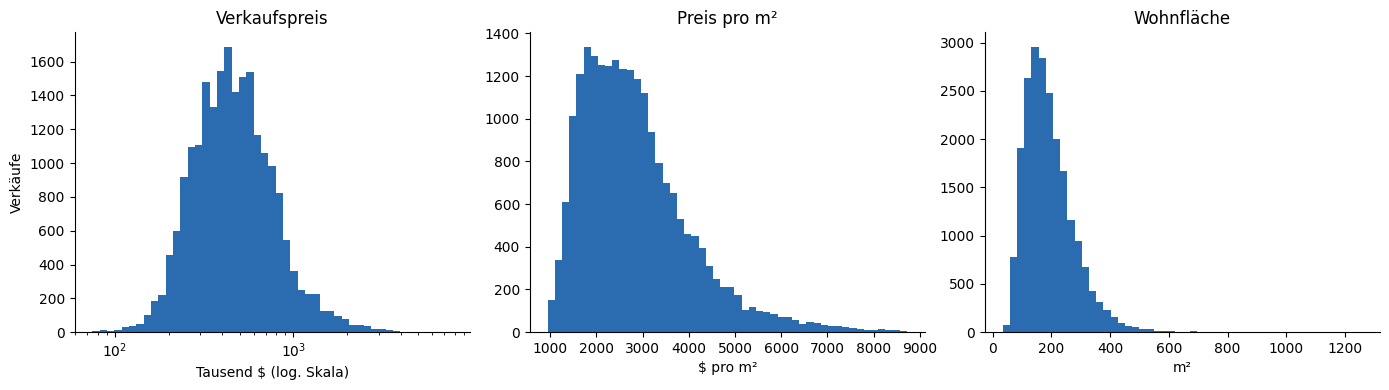

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(df.price / 1000, bins=np.logspace(np.log10(75), np.log10(7700), 50), color=BLAU)
axes[0].set(xscale="log", title="Verkaufspreis", xlabel="Tausend $ (log. Skala)", ylabel="Verkäufe")
axes[1].hist(df.preis_m2, bins=50, color=BLAU)
axes[1].set(title="Preis pro m²", xlabel="$ pro m²")
axes[2].hist(df.wohnflaeche_m2, bins=50, color=BLAU)
axes[2].set(title="Wohnfläche", xlabel="m²")
plt.tight_layout(); speichern(fig, "verteilungen"); plt.show()

Der Verkaufspreis ist stark rechtsschief, deshalb die logarithmische Skala. Der Preis pro m² und die Wohnfläche sind ebenfalls rechtsschief, aber weniger stark. Das rechtfertigt den Median als Vergleichsmaß.

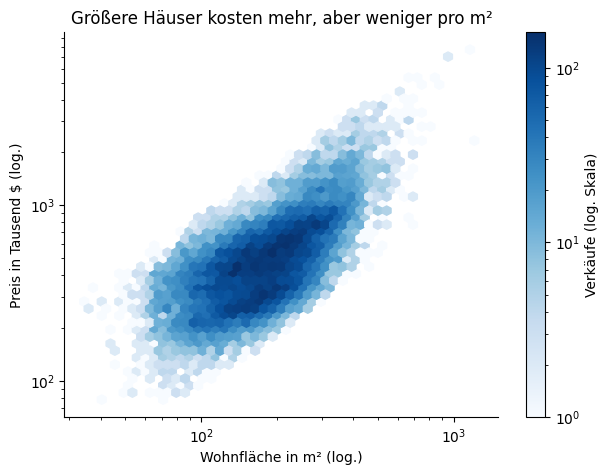

Pearson log(Fläche) zu log(Preis): 0.67
Spearman Fläche zu Preis pro m²:   -0.18


In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(df.wohnflaeche_m2, df.price / 1000, gridsize=45, xscale="log", yscale="log", bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=ax, label="Verkäufe (log. Skala)")
ax.set(title="Größere Häuser kosten mehr, aber weniger pro m²", xlabel="Wohnfläche in m² (log.)", ylabel="Preis in Tausend $ (log.)")
speichern(fig, "groesse_preis"); plt.show()
print("Pearson log(Fläche) zu log(Preis):", round(df.log_flaeche.corr(df.log_preis), 2))
print("Spearman Fläche zu Preis pro m²:  ", round(df.wohnflaeche_m2.corr(df.preis_m2, method="spearman"), 2))

Der Gesamtpreis steigt deutlich mit der Wohnfläche. Der Preis pro m² sinkt dagegen leicht mit der Größe. Für H1 ist das wichtig: Renovierte Häuser sind im Schnitt größer, ein reiner Vergleich pro m² benachteiligt sie also leicht.

## 6. H1: Renovierung

### 6.1 Roher Vergleich (Reproduktion des Originals)

In [17]:
h1 = df[df.renoviert != "unbekannt"]
roh = h1.groupby("renoviert").agg(
    verkaeufe=("price", "size"), preis_m2_median=("preis_m2", "median"), wohnflaeche_m2=("wohnflaeche_m2", "median"),
    baujahr=("yr_built", "median"), entfernung_km=("entfernung_km", "median"),
    anteil_wasser=("waterfront", "mean"), grade=("grade", "median"))
print(f"Roher Unterschied Preis pro m²: {(roh.preis_m2_median['ja'] / roh.preis_m2_median['nein'] - 1) * 100:+.1f} %")
ohne_33 = h1[~h1.schlafzimmer_verdaechtig].groupby("renoviert").preis_m2.median()
print(f"ohne das 33-Zimmer-Haus:        {(ohne_33['ja'] / ohne_33['nein'] - 1) * 100:+.1f} %")
roh.round(3)

Roher Unterschied Preis pro m²: +24.2 %
ohne das 33-Zimmer-Haus:        +24.2 %


,verkaeufe,preis_m2_median,wohnflaeche_m2,baujahr,entfernung_km,anteil_wasser,grade
renoviert,,,,,,,
ja,744,3246.102,204.380,1941.500,10.439,0.044,8.000
nein,17005,2613.189,177.439,1977.000,16.827,0.006,7.000


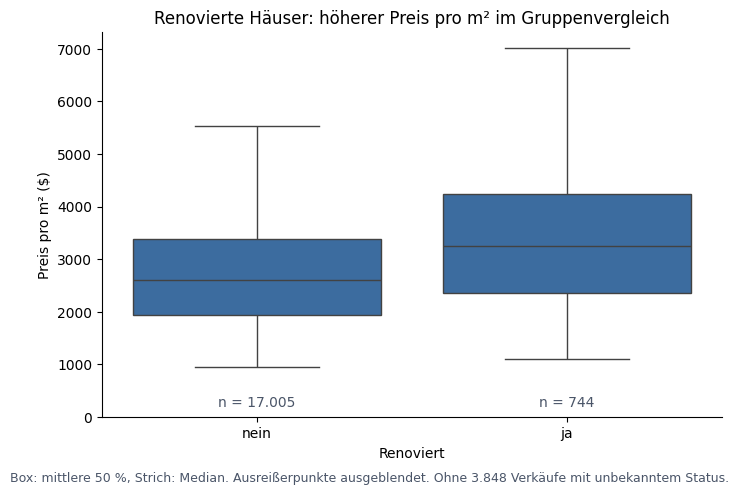

In [18]:
fig, ax = plt.subplots()
sns.boxplot(data=h1, x="renoviert", y="preis_m2", order=["nein", "ja"], showfliers=False, color=BLAU, ax=ax)
for i, gruppe in enumerate(["nein", "ja"]):
    ax.text(i, 200, f"n = {(h1.renoviert == gruppe).sum():,}".replace(",", "."), ha="center", color="#4a5568")
ax.set(title="Renovierte Häuser: höherer Preis pro m² im Gruppenvergleich",
       xlabel="Renoviert", ylabel="Preis pro m² ($)", ylim=(0, None))
fig.text(0.01, -0.02, "Box: mittlere 50 %, Strich: Median. Ausreißerpunkte ausgeblendet. Ohne 3.848 Verkäufe mit unbekanntem Status.", fontsize=9, color="#4a5568")
speichern(fig, "h1_boxplot"); plt.show()

Der rohe Unterschied von rund 24 % ist reproduziert. Er ändert sich nicht, wenn man das 33-Zimmer-Haus weglässt. Die Tabelle zeigt aber, wie verschieden die Gruppen sind: Renovierte Häuser sind größer, deutlich älter, liegen näher am Zentrum, haben eine etwas höhere Qualitätsnote (`grade`) und liegen rund siebenmal so oft am Wasser. Jeder dieser Unterschiede kann einen Teil des Preisabstands erklären.

### 6.2 Vergleich innerhalb derselben PLZ

Das Original hat eine Mindestzahl nur für die renovierte Gruppe verlangt. Hier müssen **beide** Gruppen in einer PLZ mindestens die Mindestzahl erreichen. Als Standard gelten 10 Verkäufe je Gruppe: Ein Median aus 5 Werten schwankt stark, ab 10 ist er etwas stabiler, ohne zu viele PLZ zu verlieren. 5 und 20 werden als Empfindlichkeitsprüfung mitgerechnet.

Der Median der PLZ-Aufschläge gewichtet jede PLZ gleich, egal wie viele Verkäufe sie hat. Er ist eine Beschreibung der typischen PLZ, kein allgemein bereinigter Renovierungseffekt.

In [19]:
def plz_aufschlaege(daten, spalte, mindestens):
    t = daten[daten[spalte].isin(["ja", "nein"])].groupby(["zipcode", spalte]).preis_m2.agg(["median", "size"]).unstack()
    t = t[(t["size"]["ja"] >= mindestens) & (t["size"]["nein"] >= mindestens)]
    return (t["median"]["ja"] / t["median"]["nein"] - 1) * 100


def cluster_stichprobe(daten):
    """Zieht Immobilien mit Zurücklegen. Alle Verkäufe einer gezogenen Immobilie kommen mit (Mehrfachverkäufe bleiben zusammen)."""
    codes, uniques = pd.factorize(daten.id)
    gezogen = np.bincount(rng.integers(0, len(uniques), len(uniques)), minlength=len(uniques))
    return daten.iloc[np.repeat(np.arange(len(daten)), gezogen[codes])]


def bootstrap_median_plz(daten, spalte, mindestens, plz_auswahl, wiederholungen=200):
    """95-%-Intervall für den Median der PLZ-Aufschläge."""
    daten = daten[daten.zipcode.isin(plz_auswahl)]
    werte = [plz_aufschlaege(cluster_stichprobe(daten), spalte, mindestens).median() for _ in range(wiederholungen)]
    return np.nanpercentile(werte, [2.5, 97.5])


# Original-Logik zum Vergleich: Mindestzahl nur für "ja", ursprüngliche 10-Jahres-Bedingung inkl. der 6 Fälle
def original_aufschlag(daten, ja_maske, nein_maske):
    d = daten[ja_maske | nein_maske].assign(g=np.where(ja_maske[ja_maske | nein_maske], "ja", "nein"))
    t = d.groupby(["zipcode", "g"]).preis_m2.agg(["median", "size"]).unstack()
    t = t[t["size"]["ja"] >= 5]
    a = (t["median"]["ja"] / t["median"]["nein"] - 1) * 100
    return len(a), a.median(), (ja_maske).sum()

alt10_ja = (ren > 0) & (abstand <= 10)
alt10_nein = ren.notna() & ~alt10_ja
print("Original reproduziert, jemals renoviert:  PLZ=%d  Median=%.1f %%  n_ja=%d" % original_aufschlag(df, ren > 0, ren == 0))
print("Original reproduziert, 10 Jahre:          PLZ=%d  Median=%.1f %%  n_ja=%d" % original_aufschlag(df, alt10_ja, alt10_nein))

Original reproduziert, jemals renoviert:  PLZ=47  Median=3.4 %  n_ja=744
Original reproduziert, 10 Jahre:          PLZ=24  Median=6.8 %  n_ja=283


In [20]:
zeilen = []
for mindestens in [5, 10, 20]:
    a_alle = plz_aufschlaege(df, "renoviert", mindestens)
    a_10 = plz_aufschlaege(df, "renoviert_10j", mindestens)
    gemeinsam = a_alle.index.intersection(a_10.index)
    zeilen.append({"Mindestzahl je Gruppe": mindestens,
                   "PLZ jemals": len(a_alle), "Median jemals %": a_alle.median(),
                   "PLZ 10 J.": len(a_10), "Median 10 J. %": a_10.median(),
                   "gemeinsame PLZ": len(gemeinsam),
                   "jemals, gemeinsame PLZ %": a_alle[gemeinsam].median(),
                   "10 J., gemeinsame PLZ %": a_10[gemeinsam].median()})
empfindlichkeit = pd.DataFrame(zeilen).set_index("Mindestzahl je Gruppe")
empfindlichkeit.round(1)

,PLZ jemals,Median jemals %,PLZ 10 J.,Median 10 J. %,gemeinsame PLZ,"jemals, gemeinsame PLZ %","10 J., gemeinsame PLZ %"
Mindestzahl je Gruppe,,,,,,,
5,47,3.400,22,7.400,22,3.200,7.400
10,29,2.600,11,7.200,11,6.200,7.200
20,14,2.800,0,NaN,0,NaN,NaN


In [21]:
a_alle_10 = plz_aufschlaege(df, "renoviert", 10)
ki = bootstrap_median_plz(df[df.renoviert != "unbekannt"], "renoviert", 10, a_alle_10.index)
print(f"Median PLZ-Aufschlag jemals renoviert (Mindestzahl 10): {a_alle_10.median():.1f} %, 95-%-Intervall {ki[0]:.1f} bis {ki[1]:.1f} %")
print(f"PLZ mit positivem Aufschlag: {(a_alle_10 > 0).sum()} von {len(a_alle_10)}")

Median PLZ-Aufschlag jemals renoviert (Mindestzahl 10): 2.6 %, 95-%-Intervall -0.4 bis 6.4 %
PLZ mit positivem Aufschlag: 17 von 29


- Die Original-Ergebnisse (3,4 % über 47 PLZ, 6,8 % über 24 PLZ, 283 Fälle) sind mit der Original-Logik reproduziert.
- Mit der Mindestzahl für beide Gruppen und der korrigierten 10-Jahres-Definition ändern sich Zahl der PLZ und Aufschläge. Die Tabelle zeigt, wie stark die Werte von der gewählten Mindestzahl abhängen.
- Ein fairer Vergleich der beiden Definitionen ist nur auf denselben PLZ möglich (Spalten „gemeinsame PLZ“). 47 gegen 24 verschiedene Gebiete waren im Original nicht direkt vergleichbar.
- Mit Mindestzahl 10 liegt der Median der PLZ-Aufschläge bei 2,6 %, das 95-%-Intervall reicht von -0,4 bis 6,4 %. Es schließt 0 ein: Der PLZ-Vergleich allein belegt keinen Aufschlag. Renovierte Häuser liegen nur in 17 von 29 PLZ vorne. (Ziehen nach Immobilien hält Mehrfachverkäufe zusammen.)
- Bei einer Mindestzahl von 20 je Gruppe bleibt für die 10-Jahres-Definition keine PLZ übrig. Für kurze Renovierungsfenster trägt der PLZ-Vergleich also nur mit kleinen Fallzahlen.

### 6.3 Mehrere Merkmale gleichzeitig: Modell für den Gesamtpreis

Größe und Lage wurden im Original getrennt betrachtet. Ein lineares Modell für den logarithmierten Gesamtpreis berücksichtigt sie gleichzeitig, schrittweise ergänzt um Alter, Verkaufsmonat und Wasserlage. Der Koeffizient für „renoviert“ lässt sich als prozentualer Preisunterschied lesen, bei sonst gleichen Merkmalen im Modell. Die Standardfehler sind nach Immobilie gruppiert, weil Mehrfachverkäufe nicht unabhängig sind.

**Zur Rolle von `grade` und `condition`:** Beide beschreiben Unterschiede zwischen Häusern, können aber selbst Folge einer Renovierung sein. Wer sie ins Modell nimmt, zieht einen Teil des möglichen Renovierungseffekts heraus. Deshalb laufen sie nur als Empfindlichkeitsprüfung mit, nicht im Hauptmodell.

In [22]:
h1m = df[df.renoviert != "unbekannt"].assign(ren_ja=lambda d: (d.renoviert == "ja").astype(int))
schritte = {
    "nur Renovierung": "log_preis ~ ren_ja",
    "+ Wohnfläche": "log_preis ~ ren_ja + log_flaeche",
    "+ PLZ": "log_preis ~ ren_ja + log_flaeche + C(zipcode)",
    "+ Alter, Monat": "log_preis ~ ren_ja + log_flaeche + C(zipcode) + alter + I(alter**2) + C(monat)",
    "+ Wasserlage (Hauptmodell)": "log_preis ~ ren_ja + log_flaeche + C(zipcode) + alter + I(alter**2) + C(monat) + C(wasser)",
    "+ grade, condition (Prüfung)": "log_preis ~ ren_ja + log_flaeche + C(zipcode) + alter + I(alter**2) + C(monat) + C(wasser) + C(grade) + C(condition)",
}
ergebnisse = []
for name, formel in schritte.items():
    m = smf.ols(formel, h1m).fit(cov_type="cluster", cov_kwds={"groups": h1m["id"]})
    unten, oben = m.conf_int().loc["ren_ja"]
    ergebnisse.append({"Modell": name, "Unterschied %": prozent(m.params["ren_ja"]),
                       "95-%-Intervall von": prozent(unten), "bis": prozent(oben), "R²": m.rsquared, "n": int(m.nobs)})
modelle_h1 = pd.DataFrame(ergebnisse).set_index("Modell")
modelle_h1.round(3)

,Unterschied %,95-%-Intervall von,bis,R²,n
Modell,,,,,
nur Renovierung,36.137,30.082,42.475,0.014,17749
+ Wohnfläche,24.447,20.609,28.407,0.463,17749
+ PLZ,8.493,6.198,10.837,0.818,17749
"+ Alter, Monat",8.407,6.035,10.831,0.823,17749
+ Wasserlage (Hauptmodell),6.203,4.076,8.373,0.836,17749
"+ grade, condition (Prüfung)",7.504,5.577,9.467,0.870,17749


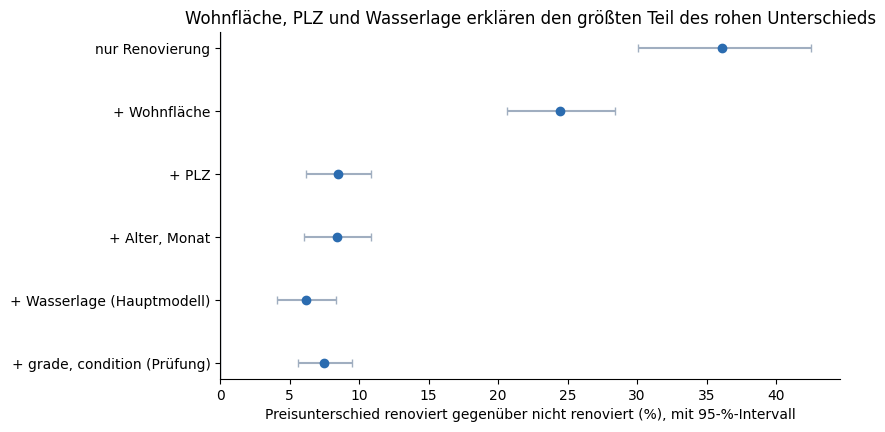

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(len(modelle_h1))[::-1]
ax.errorbar(modelle_h1["Unterschied %"], y,
            xerr=[modelle_h1["Unterschied %"] - modelle_h1["95-%-Intervall von"], modelle_h1["bis"] - modelle_h1["Unterschied %"]],
            fmt="o", color=BLAU, ecolor=GRAU, capsize=3)
ax.set_yticks(y, modelle_h1.index)
ax.axvline(0, color="#4a5568", linewidth=1)
ax.set(title="Wohnfläche, PLZ und Wasserlage erklären den größten Teil des rohen Unterschieds",
       xlabel="Preisunterschied renoviert gegenüber nicht renoviert (%), mit 95-%-Intervall", xlim=(0, None))
speichern(fig, "h1_modelle"); plt.show()

In [24]:
# "Unbekannt" als eigene Gruppe statt Ausschluss
m_unb = smf.ols("log_preis ~ C(renoviert, Treatment('nein')) + log_flaeche + C(zipcode) + alter + I(alter**2) + C(monat) + C(wasser)",
                df).fit(cov_type="cluster", cov_kwds={"groups": df["id"]})
for stufe in ["ja", "unbekannt"]:
    k = f"C(renoviert, Treatment('nein'))[T.{stufe}]"
    u, o = m_unb.conf_int().loc[k]
    print(f"{stufe:10s} gegenüber nie renoviert: {prozent(m_unb.params[k]):+.1f} % ({prozent(u):+.1f} bis {prozent(o):+.1f} %)")

ja         gegenüber nie renoviert: +6.1 % (+4.0 bis +8.3 %)
unbekannt  gegenüber nie renoviert: +0.4 % (-0.4 bis +1.1 %)


In [25]:
# Renovierungsfenster als Empfindlichkeitsprüfung: renoviert 0 bis X Jahre vor dem Verkauf gegenüber nie renoviert
fenster = []
for jahre in [5, 10, 15, 20]:
    innen = (ren > 0) & abstand.between(0, jahre)
    d = df[innen | (ren == 0)].assign(ren_ja=lambda x: ((x.renovierungsjahr > 0)).astype(int))
    m = smf.ols("log_preis ~ ren_ja + log_flaeche + C(zipcode) + alter + I(alter**2) + C(monat) + C(wasser)", d).fit(
        cov_type="cluster", cov_kwds={"groups": d["id"]})
    u, o = m.conf_int().loc["ren_ja"]
    fenster.append({"Fenster (Jahre)": jahre, "renovierte Verkäufe": int(innen.sum()),
                    "Unterschied %": prozent(m.params["ren_ja"]), "von": prozent(u), "bis": prozent(o)})
pd.DataFrame(fenster).set_index("Fenster (Jahre)").round(1)

,renovierte Verkäufe,Unterschied %,von,bis
Fenster (Jahre),,,,
5,158,12.500,8.300,16.800
10,277,11.600,8.300,14.900
15,385,11.300,8.500,14.200
20,449,11.000,8.300,13.700


### 6.4 Ergebnis H1

- **Teilweise bestätigt, als Zusammenhang.** Renovierte Häuser erzielen auch bei gleicher Größe, gleicher PLZ, gleichem Alter, gleichem Verkaufsmonat und gleicher Wasserlage einen höheren Gesamtpreis. Der Unterschied ist deutlich kleiner als im rohen Vergleich. Die genauen Werte und Intervalle stehen in den Tabellen oben.
- Im Hauptmodell (Wohnfläche, PLZ, Alter, Monat, Wasserlage) liegt der Unterschied bei **+6,2 %** (95-%-Intervall 4,1 bis 8,4 %), roh waren es +36 % beim Gesamtpreis. Den größten Teil des rohen Abstands erklären Wohnfläche und PLZ, die Wasserlage senkt ihn weiter. Alter und Verkaufsmonat ändern kaum etwas. Mit `grade` und `condition` liegt er bei +7,5 %, das Ergebnis hängt also nicht an dieser Entscheidung.
- Der PLZ-Median aus dem Original lag niedriger als das Modell. Ein Grund: Der Preis pro m² sinkt mit der Größe, und renovierte Häuser sind größer. Der Vergleich pro m² hat den Unterschied deshalb eher unterschätzt.
- Häuser, die 0 bis 10 Jahre vor dem Verkauf renoviert wurden, liegen gegenüber nie renovierten Häusern bei +11,6 % (8,3 bis 14,9 %, 277 Verkäufe). Je nach Fenster (5 bis 20 Jahre) liegt der Wert zwischen 12,5 und 11,0 %. Die Intervalle überlappen stark, ein klarer Trend nach Alter der Renovierung lässt sich daraus nicht ablesen. Achtung: Dieser Vergleich läuft gegen nie renovierte Häuser, der PLZ-Vergleich in 6.2 dagegen gegen alle nicht im Fenster renovierten.
- Häuser mit unbekanntem Status liegen im Modell bei +0,4 % (-0,4 bis +1,1 %) gegenüber nie renovierten, also praktisch gleichauf. Der Aufschlag für renovierte Häuser bleibt mit ihnen als eigener Gruppe bei +6,1 %. Ihr Ausschluss verzerrt den Vergleich nach diesen Daten kaum.
- **Was das nicht ist:** keine Renovierungsrendite. Kosten, Umfang der Renovierung und der Preis, den dasselbe Haus ohne Renovierung erzielt hätte, fehlen. Renovierte Häuser können sich in weiteren, nicht erfassten Punkten unterscheiden. Aus diesen Zahlen lässt sich kein Renovierungsbudget ableiten.

## 7. H2: Lage

### 7.1 Entfernung zum Zentrum (Reproduktion des Originals)

In [26]:
rho = df.entfernung_km.corr(df.preis_m2, method="spearman")
print(f"Spearman Entfernung zu Preis pro m²: {rho:.2f}")
zonen = pd.cut(df.entfernung_km, [0, 5, 10, 15, 20, 30, 80],
               labels=["bis 5 km", "5–10 km", "10–15 km", "15–20 km", "20–30 km", "über 30 km"])
nach_entfernung = df.groupby(zonen, observed=True).agg(verkaeufe=("price", "size"), preis_m2_median=("preis_m2", "median"))
nach_entfernung.round(0)

Spearman Entfernung zu Preis pro m²: -0.62


,verkaeufe,preis_m2_median
entfernung_km,,
bis 5 km,1343,3977.000
5–10 km,4275,3647.000
10–15 km,3799,2942.000
15–20 km,3962,2562.000
20–30 km,4455,2350.000
über 30 km,3763,1805.000


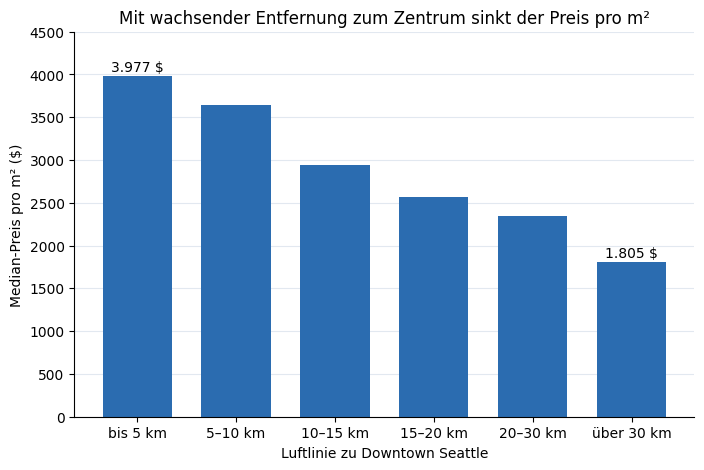

In [27]:
fig, ax = plt.subplots()
ax.bar(nach_entfernung.index.astype(str), nach_entfernung.preis_m2_median, color=BLAU, width=0.7)
for i in [0, len(nach_entfernung) - 1]:
    wert = nach_entfernung.preis_m2_median.iloc[i]
    ax.text(i, wert + 60, f"{wert:,.0f} $".replace(",", "."), ha="center")
ax.set(title="Mit wachsender Entfernung zum Zentrum sinkt der Preis pro m²",
       xlabel="Luftlinie zu Downtown Seattle", ylabel="Median-Preis pro m² ($)", ylim=(0, 4500))
ax.grid(axis="y", color="#e2e8f0"); ax.set_axisbelow(True)
speichern(fig, "h2_entfernung"); plt.show()

Die Werte des Originals sind reproduziert. Die Rangkorrelation von -0,62 bedeutet: Je weiter entfernt, desto niedriger ist tendenziell der Rang beim Preis pro m². Sie sagt nicht, welcher Anteil der Preisunterschiede durch die Entfernung erklärt wird, und sie belegt keine Ursache. „Über 30 km“ ist kein einheitlicher Stadtrand, sondern umfasst Vororte im Süden ebenso wie ländliche Gebiete im Osten.

### 7.2 Lage im Vergleich mit anderen Merkmalen

Gesamtpreis und Preis pro m² werden getrennt betrachtet. Pearson misst lineare Zusammenhänge, Spearman Rangzusammenhänge (robust gegen Ausreißer und schiefe Verteilungen). `id`, `sale_id` und die PLZ sind Kennungen und werden nicht als Zahlen korreliert.

In [28]:
merkmale = {"sqft_living": "Wohnfläche", "grade": "Qualitätsnote", "bathrooms": "Bäder", "yr_built": "Baujahr", "entfernung_km": "Entfernung"}
korr = pd.DataFrame({
    "Preis Pearson (log)": {v: df[k].corr(df.log_preis) for k, v in merkmale.items()},
    "Preis Spearman": {v: df[k].corr(df.price, method="spearman") for k, v in merkmale.items()},
    "Preis/m² Pearson": {v: df[k].corr(df.preis_m2) for k, v in merkmale.items()},
    "Preis/m² Spearman": {v: df[k].corr(df.preis_m2, method="spearman") for k, v in merkmale.items()},
})
korr.round(2)

,Preis Pearson (log),Preis Spearman,Preis/m² Pearson,Preis/m² Spearman
Wohnfläche,0.700,0.640,-0.090,-0.180
Qualitätsnote,0.700,0.660,0.130,0.120
Bäder,0.550,0.500,-0.090,-0.110
Baujahr,0.080,0.100,-0.290,-0.240
Entfernung,-0.350,-0.350,-0.550,-0.620


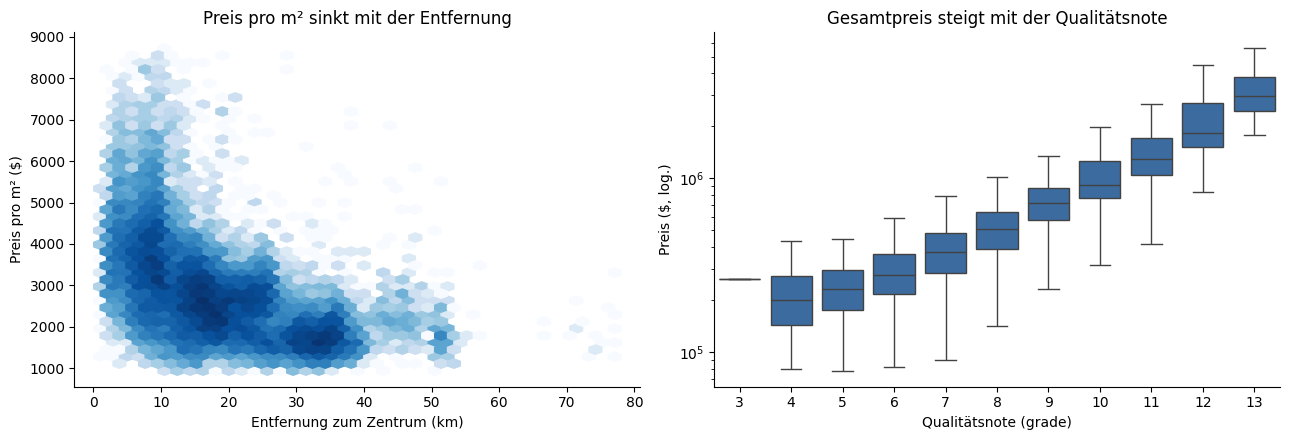

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hexbin(df.entfernung_km, df.preis_m2, gridsize=40, cmap="Blues", mincnt=1, bins="log")
axes[0].set(title="Preis pro m² sinkt mit der Entfernung", xlabel="Entfernung zum Zentrum (km)", ylabel="Preis pro m² ($)")
sns.boxplot(data=df, x="grade", y="price", showfliers=False, color=BLAU, ax=axes[1])
axes[1].set(yscale="log", title="Gesamtpreis steigt mit der Qualitätsnote", xlabel="Qualitätsnote (grade)", ylabel="Preis ($, log.)")
plt.tight_layout(); speichern(fig, "h2_merkmale"); plt.show()

In [30]:
# Wie viel der Preisunterschiede erklärt ein Merkmal allein (R²)? PLZ hat 70 Kategorien und damit viele Freiheitsgrade.
erklaert = pd.DataFrame({
    "Gesamtpreis (log)": {n: smf.ols(f"log_preis ~ {f}", df).fit().rsquared for n, f in
                          [("Wohnfläche", "log_flaeche"), ("PLZ", "C(zipcode)"), ("Qualitätsnote", "C(grade)"), ("Entfernung", "entfernung_km")]},
    "Preis pro m² (log)": {n: smf.ols(f"np.log(preis_m2) ~ {f}", df).fit().rsquared for n, f in
                           [("Wohnfläche", "log_flaeche"), ("PLZ", "C(zipcode)"), ("Qualitätsnote", "C(grade)"), ("Entfernung", "entfernung_km")]},
})
erklaert.round(3)

,Gesamtpreis (log),Preis pro m² (log)
Wohnfläche,0.455,0.030
PLZ,0.530,0.609
Qualitätsnote,0.497,0.034
Entfernung,0.124,0.337


- Beim **Gesamtpreis** erklären PLZ, Qualitätsnote und Wohnfläche jeweils für sich einen ähnlich großen Anteil. Die Lage ist dort ein wichtiger Faktor unter mehreren, nicht eindeutig der stärkste.
- Beim **Preis pro m²** erklärt die PLZ allein deutlich mehr als Qualitätsnote oder Wohnfläche. Hier ist die Lage das prägende Merkmal.
- Die Entfernung allein erklärt weniger als die PLZ. Die Luftlinie erfasst also nur einen Teil dessen, was „Lage“ ausmacht.
- Das Original hatte „Lage ist der stärkste Preisfaktor“ ohne diesen Vergleich behauptet. Die Aussage gilt nur für den Preis pro m².

### 7.3 Karte

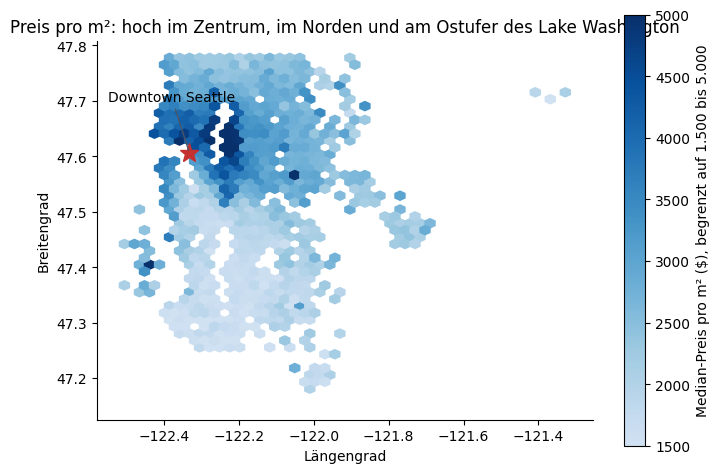

Anteil Verkäufe unter 1.500 $/m²: 7.6 %, über 5.000 $/m²: 5.5 %


In [31]:
from matplotlib.colors import ListedColormap

blau = ListedColormap(plt.cm.Blues(np.linspace(0.2, 1, 256)))
fig, ax = plt.subplots(figsize=(8, 8))
hb = ax.hexbin(df.long, df.lat, C=df.preis_m2, reduce_C_function=np.median,
               gridsize=45, cmap=blau, mincnt=3, vmin=1500, vmax=5000)
ax.plot(-122.3321, 47.6062, marker="*", color="#c53030", markersize=14)
ax.annotate("Downtown Seattle", (-122.3321, 47.6062), xytext=(-122.55, 47.70), arrowprops=dict(arrowstyle="-", color="#4a5568"))
fig.colorbar(hb, ax=ax, label="Median-Preis pro m² ($), begrenzt auf 1.500 bis 5.000", shrink=0.7)
ax.set(title="Preis pro m²: hoch im Zentrum, im Norden und am Ostufer des Lake Washington", xlabel="Längengrad", ylabel="Breitengrad")
ax.set_aspect(1 / np.cos(np.radians(47.5)))
speichern(fig, "h2_karte"); plt.show()
print("Anteil Verkäufe unter 1.500 $/m²:", round((df.preis_m2 < 1500).mean() * 100, 1), "%, über 5.000 $/m²:", round((df.preis_m2 > 5000).mean() * 100, 1), "%")

Lesehilfe: Jede Wabe zeigt den Median der Verkäufe darin. Waben mit weniger als 3 Verkäufen bleiben leer, deshalb gibt es weiße Lücken in dünn besiedelten Gebieten. Die Farbskala ist auf 1.500 bis 5.000 $/m² begrenzt, damit die Unterschiede in der Mitte sichtbar bleiben. Werte darüber und darunter erscheinen in der dunkelsten bzw. hellsten Farbe. Das betrifft 7,6 % der Verkäufe unter 1.500 $/m² und 5,5 % über 5.000 $/m².

### 7.4 Norden und Süden bei gleicher Entfernung

Im Original stand ein Nord-Süd-Vergleich ohne sichtbare Berechnung. Definition hier: Verkäufe mit 10 bis 20 km Luftlinie zum Zentrum, „Norden“ = nördlich der Breite von Downtown (47,6062).

In [32]:
ring = df[df.entfernung_km.between(10, 20)]
ring.groupby(np.where(ring.lat > 47.6062, "Norden", "Süden")).preis_m2.agg(["size", "median"]).round(0)

,size,median
Norden,4349,2900.000
Süden,3412,2394.000


Die Werte des Originals (rund 2.900 gegenüber 2.390 $/m²) sind mit dieser Definition reproduziert. Die Richtung „nördlich oder südlich von Downtown“ ist eine grobe Einteilung. Sie fasst etwa die teure Ostseite des Sees und ländliche Gebiete im Nordosten zusammen.

### 7.5 PLZ mit Unsicherheit

In [33]:
plz = df.groupby("zipcode").preis_m2.agg(["median", "size"])
auswahl = list(plz["median"].nlargest(5).index) + list(plz["median"].nsmallest(5).index)
grenzen = {}
for z, g in df[df.zipcode.isin(auswahl)].groupby("zipcode"):
    meds = [cluster_stichprobe(g).preis_m2.median() for _ in range(500)]
    grenzen[z] = np.percentile(meds, [2.5, 97.5])
tab = plz.loc[auswahl].assign(von=[grenzen[z][0] for z in auswahl], bis=[grenzen[z][1] for z in auswahl])
print("Faktor teuerste zu günstigster PLZ (Mediane):", round(plz["median"].max() / plz["median"].min(), 1))
tab.round(0)

Faktor teuerste zu günstigster PLZ (Mediane): 3.9


,median,size,von,bis
zipcode,,,,
98039,6084.000,50,5656.000,6584.000
98004,4919.000,317,4748.000,5087.000
98109,4604.000,109,4288.000,4933.000
98112,4567.000,269,4456.000,4714.000
98119,4485.000,184,4241.000,4721.000
98023,1560.000,499,1543.000,1593.000
98032,1574.000,125,1534.000,1657.000
98001,1584.000,361,1548.000,1621.000
98002,1584.000,199,1527.000,1642.000


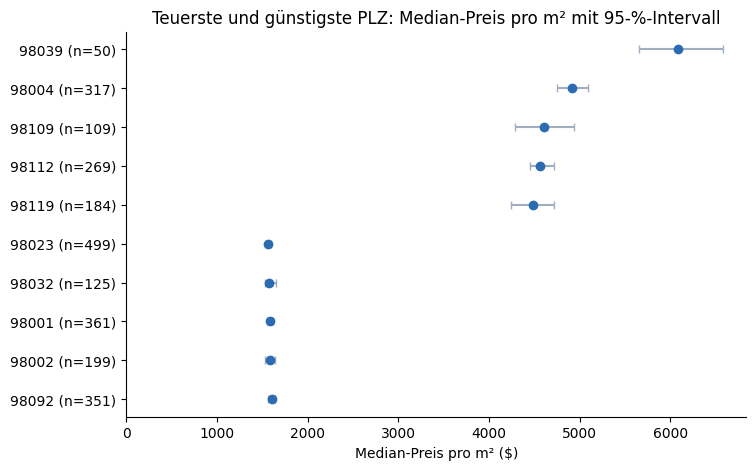

In [34]:
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(tab))[::-1]
ax.errorbar(tab["median"], y, xerr=[tab["median"] - tab.von, tab.bis - tab["median"]], fmt="o", color=BLAU, ecolor=GRAU, capsize=3)
ax.set_yticks(y, [f"{z} (n={n})" for z, n in zip(tab.index, tab["size"])])
ax.set(title="Teuerste und günstigste PLZ: Median-Preis pro m² mit 95-%-Intervall", xlabel="Median-Preis pro m² ($)", xlim=(0, None))
speichern(fig, "h2_plz"); plt.show()

### 7.6 Ergebnis H2

- **Bestätigt als enger Zusammenhang:** Der Preis pro m² sinkt mit der Entfernung zum Zentrum und unterscheidet sich stark zwischen PLZ. Für den Preis pro m² ist die Lage das prägende Merkmal, für den Gesamtpreis eines von mehreren ähnlich starken.
- Die Intervalle zeigen: Die Unterschiede zwischen den teuersten und günstigsten PLZ sind deutlich größer als die Unsicherheit der einzelnen Mediane.
- **Was das nicht ist:** Ein hoher Preis pro m² heißt nicht hohe Rendite. Teure Lagen kosten auch im Einkauf mehr. Kaufpreise und Wertsteigerungen sind nicht in den Daten.
- Der Faktor zwischen extremen PLZ beschreibt Unterschiede zwischen Gebieten. Er ist nicht mit dem Renovierungsunterschied innerhalb von PLZ vergleichbar, weil beide etwas völlig anderes messen.

## 8. H3: Verkaufszeitpunkt

### 8.1 Datenabdeckung

In [35]:
wochen = df.set_index("date").resample("W-SUN").size()
print("Verkäufe in den letzten 8 Wochen:")
print(wochen.tail(8).to_string())
mai15 = df[df.date >= "2015-05-01"]
print("\nVerkäufe je Tag im Mai 2015:", mai15.groupby(mai15.date.dt.day).size().to_dict())

Verkäufe in den letzten 8 Wochen:
date
2015-04-12    493
2015-04-19    458
2015-04-26    559
2015-05-03    536
2015-05-10    419
2015-05-17    132
2015-05-24      1
2015-05-31      1
Freq: W-SUN

Verkäufe je Tag im Mai 2015: {1: 77, 2: 6, 3: 10, 4: 102, 5: 94, 6: 88, 7: 76, 8: 54, 9: 3, 10: 2, 11: 40, 12: 49, 13: 31, 14: 11, 15: 1, 24: 1, 27: 1}


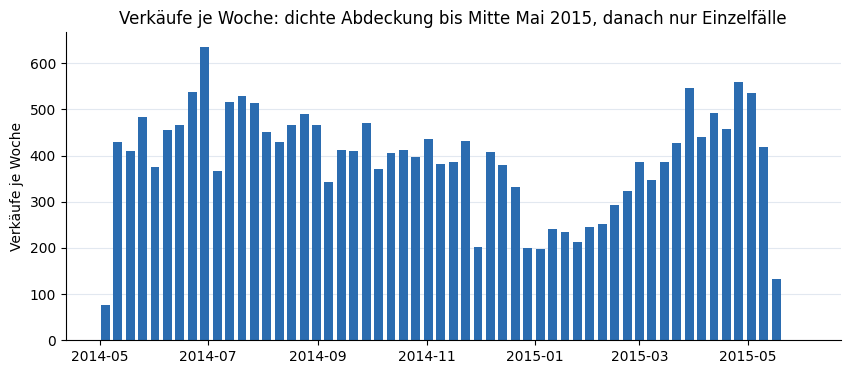

In [36]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(wochen.index, wochen.values, width=5, color=BLAU)
ax.set(title="Verkäufe je Woche: dichte Abdeckung bis Mitte Mai 2015, danach nur Einzelfälle", ylabel="Verkäufe je Woche")
ax.grid(axis="y", color="#e2e8f0"); ax.set_axisbelow(True)
speichern(fig, "h3_abdeckung"); plt.show()

Bis zum 14. Mai 2015 gibt es an Werktagen regelmäßig Verkäufe, danach nur noch je einen am 15., 24. und 27. Mai. Das späteste Datum (27. Mai) erklärt die niedrige Zahl im Mai 2015 also nicht: Die Datenreihe bricht faktisch Mitte Mai ab. Warum, geht aus den Daten nicht hervor (etwa Stichtag der Datenerhebung oder verzögert erfasste Verkäufe). Am Anfang beginnt die Reihe am 2. Mai 2014.

Folge für die Jahreszeiten: „Frühjahr“ umfasst Mai 2014 sowie März bis Mitte Mai 2015, also zwei verschiedene Jahre und eine kürzere Beobachtungszeit als „Herbst“.

In [37]:
abdeckung = df.groupby("jahreszeit").agg(verkaeufe=("price", "size"), von=("date", "min"), bis=("date", "max"),
                                         monate=("monat", lambda m: ", ".join(sorted(m.unique()))))
abdeckung.loc[["Frühjahr", "Sommer", "Herbst", "Winter"]]

,verkaeufe,von,bis,monate
jahreszeit,,,,
Frühjahr,6518,2014-05-02,2015-05-27,"2014-05, 2015-03, 2015-04, 2015-05"
Sommer,6328,2014-06-01,2014-08-31,"2014-06, 2014-07, 2014-08"
Herbst,5056,2014-09-01,2014-11-30,"2014-09, 2014-10, 2014-11"
Winter,3695,2014-12-01,2015-02-28,"2014-12, 2015-01, 2015-02"


### 8.2 Roher Vergleich (Reproduktion des Originals)

In [38]:
nach_jz = df.groupby("jahreszeit").preis_m2.median()
print(f"Frühjahr gegenüber Herbst: {(nach_jz['Frühjahr'] / nach_jz['Herbst'] - 1) * 100:+.1f} %")
je_plz = df[df.jahreszeit.isin(["Frühjahr", "Herbst"])].groupby(["zipcode", "jahreszeit"]).preis_m2.median().unstack()
print(f"Median der PLZ-Unterschiede: {((je_plz['Frühjahr'] / je_plz['Herbst'] - 1) * 100).median():+.1f} %")
nach_monat = df.groupby("monat").agg(verkaeufe=("price", "size"), preis_m2_median=("preis_m2", "median"))
print(f"Mai 2015 gegenüber Mai 2014 (Mediane): {(nach_monat.preis_m2_median['2015-05'] / nach_monat.preis_m2_median['2014-05'] - 1) * 100:+.1f} %")

Frühjahr gegenüber Herbst: +4.3 %
Median der PLZ-Unterschiede: +4.8 %
Mai 2015 gegenüber Mai 2014 (Mediane): +5.3 %


### 8.3 Monatsvergleich bei gleicher Zusammensetzung

Monatsmediane vermischen drei Dinge: Saison, allgemeine Preisentwicklung und die Frage, welche Häuser gerade verkauft wurden. Ein Modell für den logarithmierten Preis mit Monat, Wohnfläche, PLZ, Alter, Wasserlage und Qualitätsnote vergleicht die Monate bei gleicher Zusammensetzung. Ergebnis ist ein Index gegenüber Mai 2014. Auch er ist kein offizieller Marktpreisindex.

In [39]:
m_zeit = smf.ols("log_preis ~ C(monat) + log_flaeche + C(zipcode) + alter + I(alter**2) + C(wasser) + C(grade)", df).fit(
    cov_type="cluster", cov_kwds={"groups": df["id"]})
index = pd.DataFrame({"monat": sorted(df.monat.unique())}).set_index("monat")
index["bereinigt %"] = 0.0; index["von"] = 0.0; index["bis"] = 0.0
for mo in index.index[1:]:
    k = f"C(monat)[T.{mo}]"
    index.loc[mo, "bereinigt %"] = prozent(m_zeit.params[k])
    index.loc[mo, ["von", "bis"]] = [prozent(x) for x in m_zeit.conf_int().loc[k]]
index["roh %"] = (nach_monat.preis_m2_median / nach_monat.preis_m2_median["2014-05"] - 1) * 100
index["verkaeufe"] = nach_monat.verkaeufe
index.round(1)

,bereinigt %,von,bis,roh %,verkaeufe
monat,,,,,
2014-05,0.000,0.000,0.000,0.000,1768
2014-06,2.000,0.800,3.200,1.700,2178
2014-07,1.300,0.100,2.500,-1.100,2211
2014-08,1.400,0.200,2.700,0.700,1939
2014-09,1.100,-0.100,2.400,-0.600,1771
2014-10,0.700,-0.600,2.000,-0.200,1876
2014-11,0.300,-1.000,1.600,-2.600,1409
2014-12,1.200,-0.200,2.600,-4.600,1470
2015-01,1.300,-0.200,2.900,-4.000,978


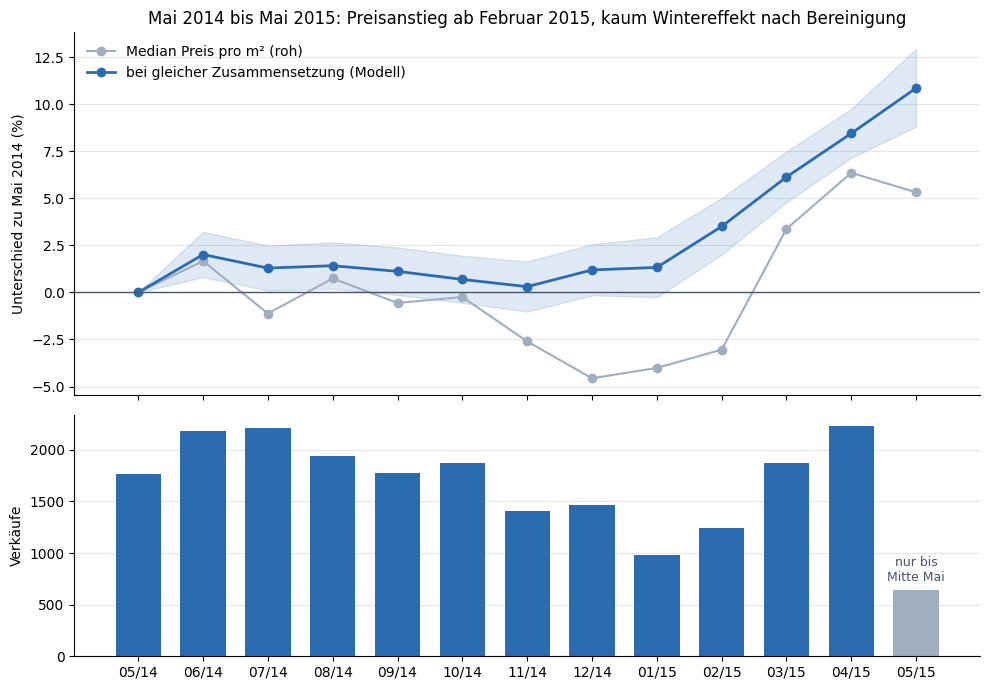

In [40]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
x = np.arange(len(index))
ax1.plot(x, index["roh %"], color=GRAU, marker="o", label="Median Preis pro m² (roh)")
ax1.plot(x, index["bereinigt %"], color=BLAU, marker="o", linewidth=2, label="bei gleicher Zusammensetzung (Modell)")
ax1.fill_between(x, index.von, index.bis, color=BLAU, alpha=0.15)
ax1.axhline(0, color="#4a5568", linewidth=1)
ax1.set(title="Mai 2014 bis Mai 2015: Preisanstieg ab Februar 2015, kaum Wintereffekt nach Bereinigung",
        ylabel="Unterschied zu Mai 2014 (%)")
ax1.legend(frameon=False)
farben = [GRAU if m in ("2015-05",) else BLAU for m in index.index]
ax2.bar(x, index.verkaeufe, color=farben, width=0.7)
ax2.set(ylabel="Verkäufe")
ax2.set_xticks(x, [m[5:] + "/" + m[2:4] for m in index.index])
ax2.text(x[-1], index.verkaeufe.iloc[-1] + 80, "nur bis\nMitte Mai", ha="center", fontsize=9, color="#4a5568")
for ax in (ax1, ax2):
    ax.grid(axis="y", color="#e2e8f0"); ax.set_axisbelow(True)
plt.tight_layout(); speichern(fig, "h3_monate"); plt.show()

### 8.4 Ergebnis H3 (beschreibend für Mai 2014 bis Mai 2015)

- Der rohe Unterschied Frühjahr gegenüber Herbst (rund +4 %) ist reproduziert.
- Bei gleicher Zusammensetzung der Verkäufe liegen die Monate von Juni 2014 bis Januar 2015 nur 0,3 bis 2,0 % über Mai 2014, also nahezu gleich. Danach steigt der Index auf +3,5 % (Februar), +6,1 % (März), +8,5 % (April) und +10,9 % (Mai 2015). Ab Februar 2015 steigen die Preise deutlich. Der Frühjahrsvorsprung fällt also mit diesem Anstieg 2015 zusammen. Ob er saisonal ist oder Teil einer allgemeinen Preisentwicklung, lässt sich mit einem Jahr Daten nicht trennen.
- Der niedrige Median im Winter (roh -4,6 % im Dezember gegenüber Mai 2014) verschwindet nach der Bereinigung weitgehend (+1,2 %). Er geht vor allem darauf zurück, welche Häuser im Winter verkauft wurden. Eine Aussage wie „Winter ist die schlechteste Verkaufszeit“ ist durch diese Daten nicht gedeckt.
- Weniger Verkäufe im Winter heißen nicht weniger Käufer oder weniger Nachfrage. Es fehlen Angebotszahlen, Inseratsdauer und Zahl der Interessenten.
- Das Verkaufsdatum ist der Abschluss, nicht der Tag des Inserats. Eine Empfehlung zum Inseratsmonat lässt sich daraus nicht direkt ableiten.
- **Für belastbare Aussagen zur Saison bräuchte es:** mehrere Jahre Verkaufsdaten, Inserats- und Abschlussdatum, Angebotsmenge und Vermarktungsdauer, idealerweise einen offiziellen Preisindex für King County.

## 9. Erkenntnisse

**1. Lage hängt eng mit dem Preis pro m² zusammen (geografisch).** Im Zentrum liegt der Median bei rund 3.980 $/m², über 30 km Entfernung bei rund 1.800 $/m². Zwischen den PLZ liegt der Faktor 3,9. Teuer sind das Zentrum, der Norden Seattles und das Ostufer des Lake Washington. Für den Preis pro m² erklärt die PLZ mehr als Größe oder Qualität, für den Gesamtpreis sind die drei ähnlich wichtig.

**2. Renovierte Häuser erzielen auch bei vergleichbaren Merkmalen mehr, aber weit weniger als im rohen Vergleich.** Roh liegen sie beim Preis pro m² 24 % vorne. Bei gleicher Wohnfläche, PLZ, Alter, Verkaufsmonat und Wasserlage bleiben rund +6 % beim Gesamtpreis (4 bis 8 %), bei Renovierung 0 bis 10 Jahre vor dem Verkauf rund +12 % gegenüber nie renovierten Häusern. Das ist ein Zusammenhang, keine Rendite.

**3. Im beobachteten Jahr steigen die Preise ab Februar 2015.** Bei gleicher Zusammensetzung liegen Juni 2014 bis Januar 2015 nahe am Niveau von Mai 2014, Mai 2015 liegt 10,9 % darüber. Ein eigener Wintereffekt zeigt sich kaum. Die Datenreihe bricht Mitte Mai 2015 ab.

## 10. Empfehlungen für Charles Christensen

**1. Bei Investitionsentscheidungen die Lage als wichtigsten Preistreiber pro m² einplanen.** Zentrum, Seattle-Nord und das Ostufer haben das höchste Preisniveau. Ob sich das als Rendite auszahlt, hängt am Kaufpreis. Den sollte Charles für konkrete Objekte mit diesen Verkaufsdaten vergleichen.

**2. Renovierung als möglichen Preisvorteil prüfen, aber nicht auf diese Zahlen allein stützen.** Renovierte Häuser erzielen in den Daten mehr, auch bei vergleichbaren Merkmalen. Ob sich eine konkrete Renovierung lohnt, braucht Kostenvoranschläge und Vergleichsverkäufe ähnlicher Häuser in derselben Lage.

**3. Den Verkaufszeitpunkt am aktuellen Marktverlauf ausrichten, nicht an einer festen Jahreszeit.** Im Datenjahr stiegen die Preise ab Februar 2015. Eine feste Regel „nicht im Winter verkaufen“ geben diese Daten nicht her.

## 11. Grenzen

- Ein Jahr Daten, dicht nur bis Mitte Mai 2015.
- Keine Kaufpreise, Kosten, Renovierungsumfänge oder Inseratsdaten, daher keine Rendite- oder Ursachenaussagen.
- PLZ und Luftlinie bilden Lage nur grob ab.
- 18 % fehlende Renovierungsangaben, nach den Prüfungen ohne erkennbares Muster.